In [1]:
from pathlib import Path

from email_outreach.utils.constants import ROOT_FOLDER

# ============================== CONFIG ==============================
EXP_ROOT = ROOT_FOLDER / "experiments" / "test_set" / "1" / "contextual_bandit"

# display name -> folder with the experiment runs (order = plotting / table order)
EXPERIMENTS: dict[str, Path] = {
    "Baseline": EXP_ROOT / "true_baseline",
    "Model": EXP_ROOT / "model",
    "Model 2": EXP_ROOT / "model_2",
}

REFERENCE = "Baseline"                          # deltas are computed vs. this experiment (None = no deltas)
N_POINTS = 101                                  # resolution of the recall/precision curves
HIGHLIGHT_X = [0.05, 0.15, 0.25, 0.35, 0.50, 0.75]   # points for the recall/precision tables
RECALL_TARGETS = [0.80, 0.90, 0.95]             # "x needed to reach recall >= target" table
ZOOM_X_MAX = 0.40                               # right edge of the zoomed plots
STD_DDOF = 0                                    # 0 = population std (as before), 1 = sample std
DECIMALS = 4
SAVE_DIR = None                                 # e.g. Path("figures") to also save PNGs
# ====================================================================

## Load experiments

In [2]:
from email_outreach.notes.experiment_summary import (
    load_experiments, show_summary_tables,
    plot_mean_curves, plot_recall_delta, plot_individual_runs, plot_auc,
)

results = load_experiments(EXPERIMENTS, n_points=N_POINTS, std_ddof=STD_DDOF, reference=REFERENCE)

Baseline: 100 runs loaded in 178s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/true_baseline)
Model: 100 runs loaded in 173s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/model)
Model 2: 84 runs loaded in 135s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/model_2)


## Summary tables

In [3]:
show_summary_tables(results, highlight_x=HIGHLIGHT_X, recall_targets=RECALL_TARGETS,
                    reference=REFERENCE, decimals=DECIMALS)

### Recall AUC

,runs,AUC mean,AUC std,AUC min,AUC max,Δ AUC vs ref (pp)
Baseline,100.0,0.8914,0.0118,0.8717,0.9107,NaN
Model,100.0,0.9136,0.0107,0.8969,0.9302,2.22
Model 2,84.0,0.9023,0.0095,0.8840,0.9197,1.08


### Recall at selected points (mean ± std over runs; columns = x = 1 - quantile)

,0.05,0.15,0.25,0.35,0.50,0.75
Baseline,0.3588 ± 0.0782,0.8185 ± 0.0242,0.9236 ± 0.0125,0.9593 ± 0.0116,0.9745 ± 0.0080,0.9879 ± 0.0043
Model,0.5178 ± 0.0324,0.8547 ± 0.0285,0.9364 ± 0.0182,0.9654 ± 0.0104,0.9761 ± 0.0074,0.9890 ± 0.0041
Model 2,0.4668 ± 0.0330,0.7924 ± 0.0301,0.9295 ± 0.0161,0.9658 ± 0.0101,0.9765 ± 0.0072,0.9897 ± 0.0036


**Δ recall vs `Baseline` (pp)**

,0.05,0.15,0.25,0.35,0.50,0.75
Model,15.9,3.61,1.28,0.61,0.16,0.11
Model 2,10.8,-2.61,0.60,0.65,0.20,0.18


... (2 outputs left out)

**Δ precision vs `Baseline` (pp)**

,0.05,0.15,0.25,0.35,0.50,0.75
Model,15.27,1.14,0.25,0.09,0.02,0.01
Model 2,10.25,-0.88,0.10,0.08,0.01,0.01


### Smallest x at which the mean recall reaches the target (lower is better)

,recall ≥ 80%,recall ≥ 90%,recall ≥ 95%
Baseline,0.15,0.22,0.32
Model,0.12,0.20,0.28
Model 2,0.16,0.22,0.29


## Recall curves

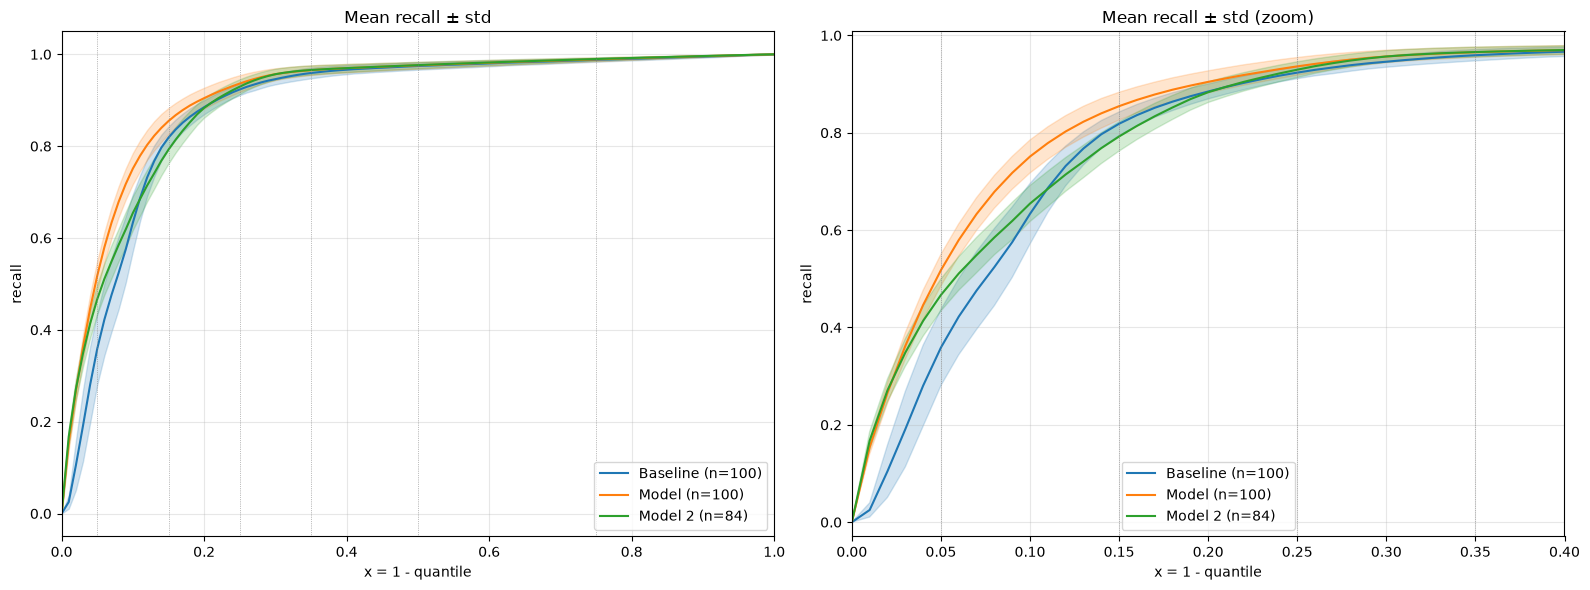

In [4]:
plot_mean_curves(results, kind="recall", highlight_x=HIGHLIGHT_X, zoom_x_max=ZOOM_X_MAX, save_dir=SAVE_DIR)

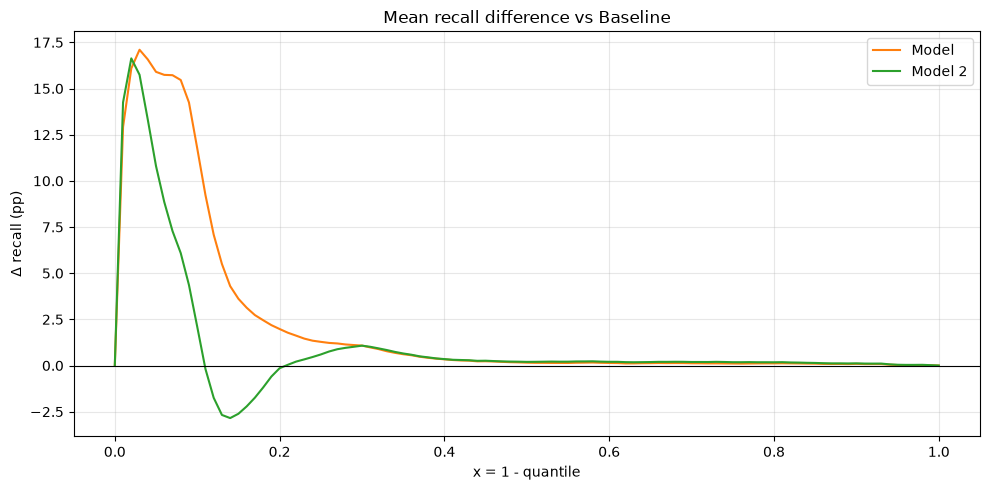

In [5]:
if REFERENCE is not None:
    plot_recall_delta(results, reference=REFERENCE, save_dir=SAVE_DIR)

## Individual runs overlaid

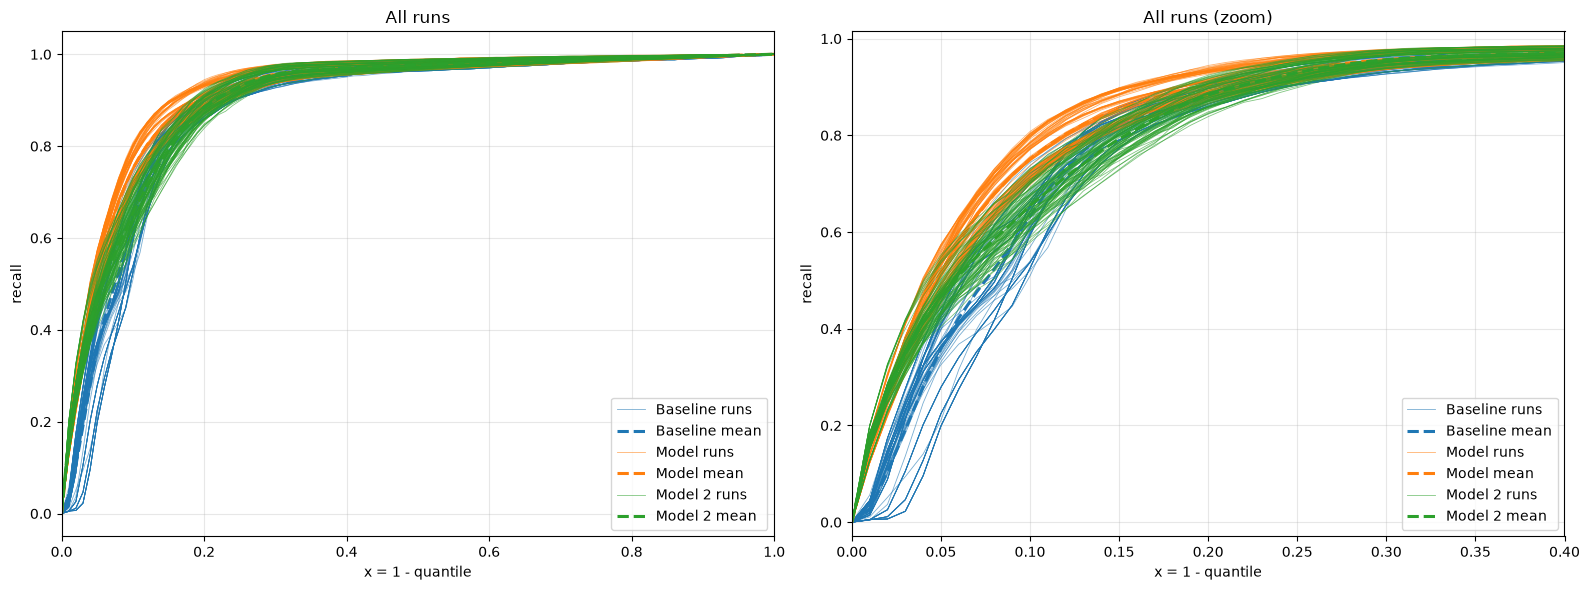

In [6]:
plot_individual_runs(results, kind="recall", zoom_x_max=ZOOM_X_MAX, save_dir=SAVE_DIR)

## Precision curves

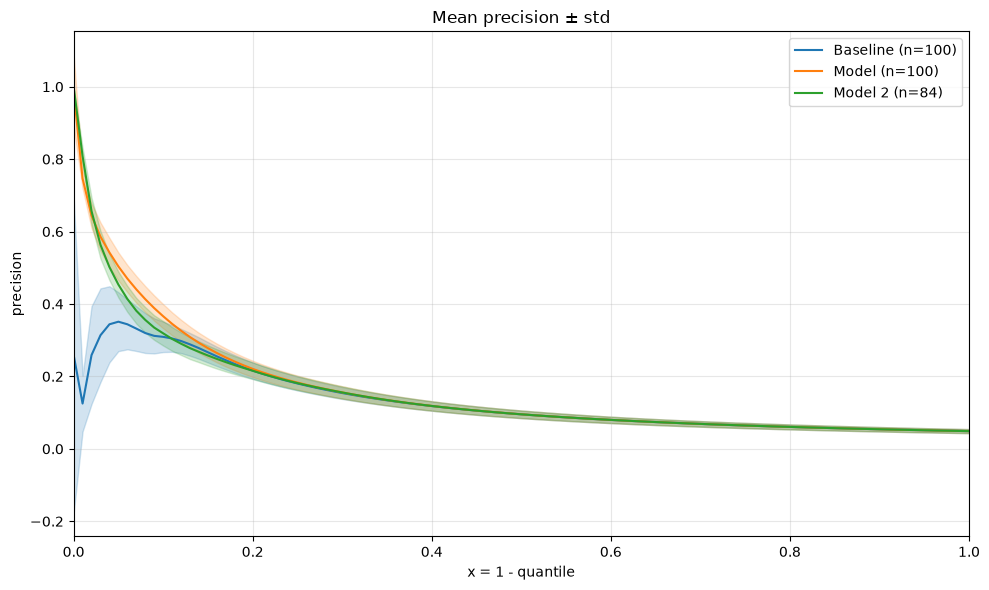

In [7]:
plot_mean_curves(results, kind="precision", save_dir=SAVE_DIR)

## Per-run AUC

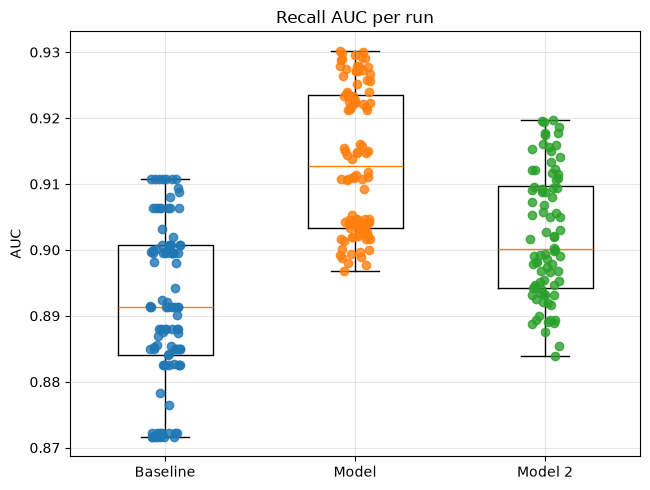

In [8]:
plot_auc(results, save_dir=SAVE_DIR)